# 01 - Data Exploration

Load the PropBank-style SRL data fetched from Hugging Face (`cu-kairos/propbank_srl_seq2seq`), inspect size and format, and plot the role distribution.

**Deliverable 1:** a short dataset description (size, format, label distribution, limits).

In [1]:
import sys, os
from pathlib import Path
# Make src/ importable whether run from repo root or notebooks/.
ROOT = Path.cwd()
if (ROOT / 'src').exists():
    sys.path.insert(0, str(ROOT / 'src'))
elif (ROOT.parent / 'src').exists():
    ROOT = ROOT.parent
    sys.path.insert(0, str(ROOT / 'src'))
os.chdir(ROOT)
print('project root:', ROOT)


project root: /Users/ellam/Documents/Projects/openai-srl-benchmark


## Build the datasets
Downloads parquet from Hugging Face and writes train/validation/test JSONL under `data/`.
Sizes are kept modest to save API credits; raise them for a larger study.

In [2]:
import data_loader as dl
counts = dl.prepare(train_size=2000, val_size=500, test_size=500, seed=13)
counts

== Building SRL datasets ==


Wrote: {
  "train": 2000,
  "validation": 500,
  "test": 500
}
(usable: train pool=2000, val pool=4662)


{'train': 2000, 'validation': 500, 'test': 500}

## Load and inspect

In [3]:
train = dl.read_jsonl('data/train.jsonl')
val = dl.read_jsonl('data/validation.jsonl')
test = dl.read_jsonl('data/test.jsonl')
print('train/val/test:', len(train), len(val), len(test))
ex = train[0]
print('example sentence:', ex.sentence)
print('predicate:', repr(ex.predicate), (ex.predicate_start, ex.predicate_end))
for a in ex.arguments:
    print(' ', a.role, repr(a.text), (a.start, a.end))

train/val/test: 2000 500 500
example sentence: The trajectory of the comet will prevent its capture by the sun .
predicate: 'capture' (45, 52)
  ARG1 'its' (41, 44)
  ARG0 'by the sun' (53, 63)


## Dataset statistics

In [4]:
from collections import Counter
import pandas as pd
all_ex = train + val + test
n_sent = len(all_ex)
n_pred = n_sent  # one predicate per example in this dataset
lemmas = Counter(e.predicate.lower() for e in all_ex)
roles = Counter(a.role for e in all_ex for a in e.arguments)
missing_offsets = sum(1 for e in all_ex for a in e.arguments if a.start is None)
print('examples (predicate instances):', n_sent)
print('unique predicate lemmas:', len(lemmas))
print('total arguments:', sum(roles.values()))
print('arguments with unresolved offsets:', missing_offsets)
print('most common predicates:', lemmas.most_common(10))
pd.Series(roles).sort_values(ascending=False).head(20)

examples (predicate instances): 3000
unique predicate lemmas: 2716
total arguments: 7355
arguments with unresolved offsets: 23
most common predicates: [('cut', 6), ('check', 5), ('go', 5), ('thrummed', 4), ('retreat', 4), ('sweep', 4), ('service', 4), ('known', 4), ('run', 4), ('good', 3)]


ARG1        2574
ARG0        1727
ARG2         956
ARGM-TMP     417
ARGM-MNR     212
ARGM-ADV     203
ARGM-MOD     174
ARG3         167
ARGM-LOC     167
ARGM-DIS     100
ARGM-NEG      85
ARGM-EXT      84
ARGM-DIR      56
ARGM-ADJ      52
R-ARG0        51
ARGM-LVB      47
ARGM-PRP      46
ARG4          38
ARGM-CAU      34
R-ARG1        33
dtype: int64

## Role distribution plot

saved /Users/ellam/Documents/Projects/openai-srl-benchmark/results/figures/role_distribution.png


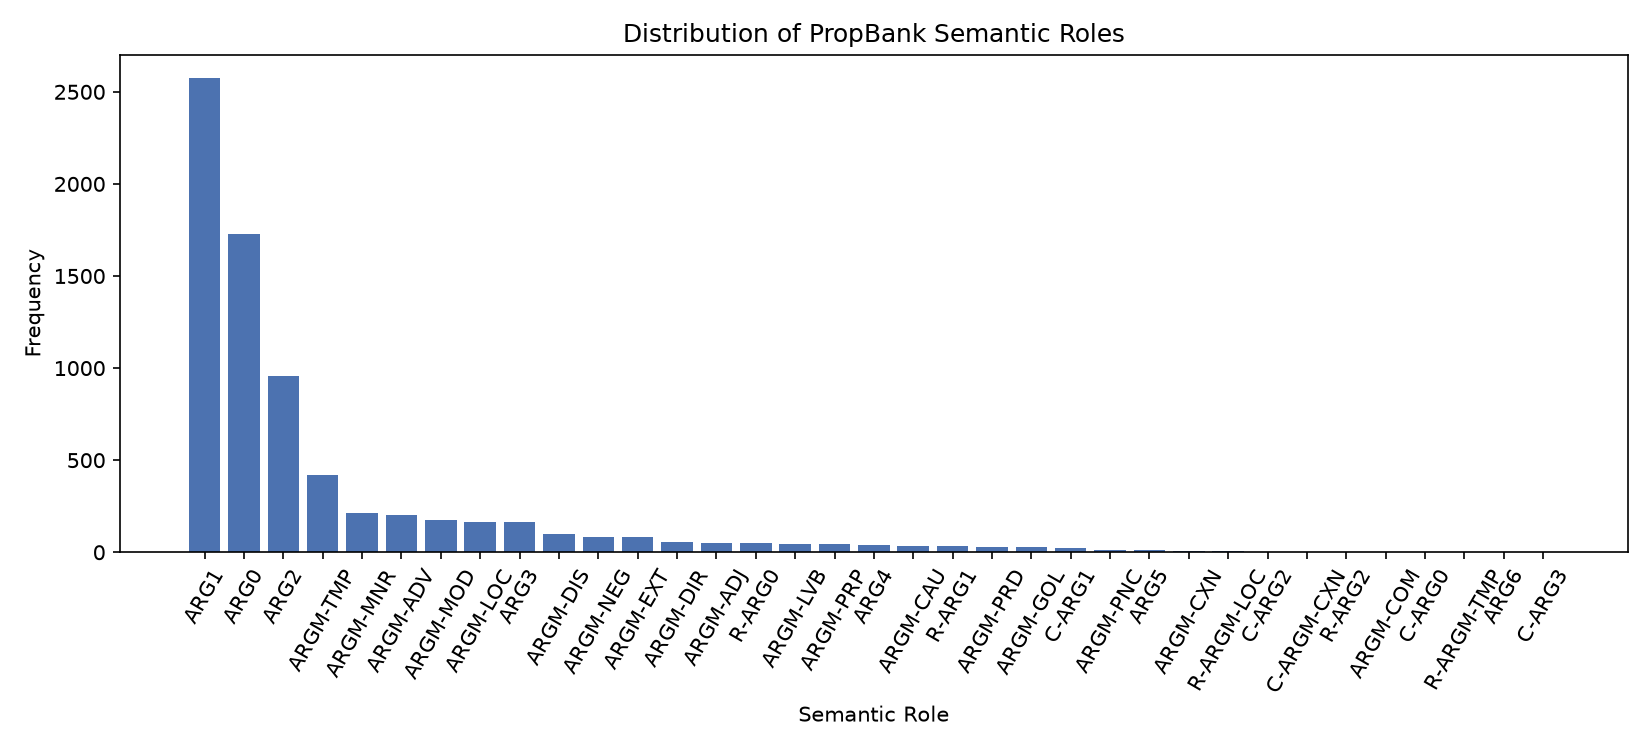

In [5]:
import visualization as viz
path = viz.plot_role_distribution(dict(roles))
print('saved', path)
from IPython.display import Image
Image(filename=str(path))

### Notes / limitations
- One annotated predicate per example (the bracketed predicate in the source).
- Source provides train + validation only; our **test** split is carved from the
  source validation split (disjoint from our validation set).
- `<unk>` rows (predicates with no annotated arguments) are dropped.
- A few argument spans may not resolve to exact character offsets; those are
  excluded from strict span scoring (see `arguments with unresolved offsets`).